In [1]:
# ============================================================
# ICE SHEET SEJ ANALYSIS SCRIPT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

In [3]:
# ============================================================
# 1. IMPORT DATA
# ============================================================

file = "../data/sej2025_Split Panel_uninet_DEP_sample_11-12-14 AM_50K_ONLYSAMPLES.xlsx"

df = pd.read_excel(file, engine="openpyxl").copy()
df = df.assign(sample_id=np.arange(len(df)))


In [5]:
# ============================================================
# 2. PARSE VARIABLE NAMES
# ============================================================

def parse_variable(col):
    # Skip non-SEJ columns
    if "_" not in col:
        return None

    var, t = col.split("_")

    # Skip invalid time codes
    if t not in {"21", "22", "23"}:
        return None

    ice = None
    process = "TOTAL"
    scenario = None

    if var.startswith("SLR"):
        ice = "SLR"
        scenario = var.replace("SLR", "")
    else:
        ice = var[0]
        if len(var) > 1 and var[1].isalpha():
            process = var[1]
            scenario = var[2:]
        else:
            scenario = var[1:]

    return {
        "variable": col,
        "ice_sheet": ice,
        "process": process,
        "scenario": scenario,
        "time": {"21":2100, "22":2200, "23":2300}[t]
    }

# Apply safely
meta_list = [parse_variable(c) for c in df.columns]
meta_list = [m for m in meta_list if m is not None]

meta = pd.DataFrame(meta_list).set_index("variable")
meta

,ice_sheet,process,scenario,time
variable,,,,
EA2_21,E,A,2,2100
EA2_22,E,A,2,2200
EA2_23,E,A,2,2300
EA35_21,E,A,35,2100
EA35_22,E,A,35,2200
...,...,...,...,...
W35_22,W,TOTAL,35,2200
W35_23,W,TOTAL,35,2300
W5_21,W,TOTAL,5,2100


In [9]:
# ============================================================
# 3. LONG FORMAT
# ============================================================


# Melt while preserving sample identity
df_long = df.melt(
    id_vars="sample_id",
    var_name="variable",
    value_name="value"
)

# Attach metadata
df_long = df_long.join(meta, on="variable")


scenario_map = {"2":"2.0°C","35":"3.5°C","5":"5.0°C"}
df_long["scenario_name"] = df_long["scenario"].map(scenario_map)



In [13]:
# ============================================================
# 4. ADD AIS (E + W)
# ============================================================

df_total = df_long[df_long["process"]=="TOTAL"].copy()

ais_list = []
for (year, scen), g in df_total.groupby(["time","scenario_name"]):
    sub = g[g["ice_sheet"].isin(["E","W"])]


    wide = sub.pivot(index="sample_id", columns="ice_sheet", values="value")

    # Ensure both exist
    wide = wide.dropna(subset=["E", "W"])

    ais_vals = wide["E"] + wide["W"]

    temp = pd.DataFrame({
        "sample_id": wide.index,
        "value": ais_vals,
        "time": year,
        "scenario_name": scen,
        "ice_sheet": "AIS",
        "process": "TOTAL"
    })

    ais_list.append(temp)


df_ais = pd.concat(ais_list, ignore_index=True)

# Combine
df_total_ext = pd.concat([df_total, df_ais], ignore_index=True)


In [15]:
# ============================================================
# 5. TABLE 1
# ============================================================


def stats(group):
    v = group.dropna()

    # Handle empty groups safely
    if len(v) == 0:
        return pd.Series({
            "Mean±SD": np.nan,
            "50%": np.nan,
            "5-95%": np.nan,
            "17-83%": np.nan
        })

    return pd.Series({
        "Mean±SD": f"{v.mean():.0f} ± {v.std():.0f}",
        "50%": f"{np.percentile(v,50):.0f}",
        "5-95%": f"{np.percentile(v,5):.0f}-{np.percentile(v,95):.0f}",
        "17-83%": f"{np.percentile(v,17):.0f}-{np.percentile(v,83):.0f}"
    })


table1 = (
    df_total_ext.groupby(["time","scenario_name","ice_sheet"])["value"]
    .apply(stats)
    .reset_index()
)

table1.to_excel("Table1.xlsx", index=False)

In [17]:
# ============================================================
# 6. TABLE 2 (PROCESS)
# ============================================================

df_proc = df_long[df_long["process"].isin(["A","D","R"])]

def quantiles(v):
    v = v.dropna()
    return pd.Series({
        "5%":np.percentile(v,5),
        "50%":np.percentile(v,50),
        "95%":np.percentile(v,95)
    })

table2 = (
    df_proc.groupby(["time","scenario_name","ice_sheet","process"])["value"]
    .apply(quantiles)
    .reset_index()
)

table2.to_excel("Table2.xlsx", index=False)

In [18]:
# ============================================================
# 7. HELPER FUNCTIONS
# ============================================================

def ranges(v):
    v = v.dropna()
    return np.percentile(v,[5,17,50,83,95])

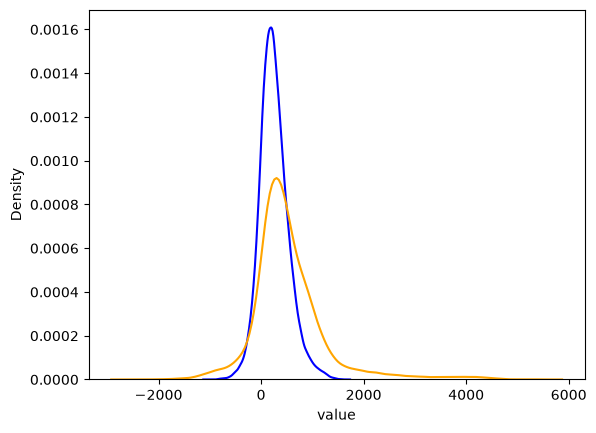

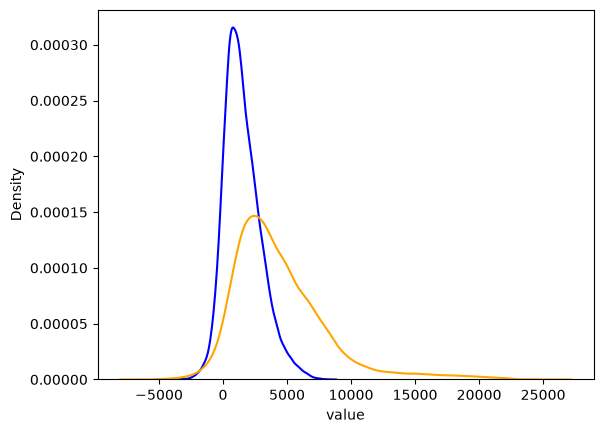

In [19]:
# ============================================================
# 8. FIGURE 1: PDFs TOTAL
# ============================================================

for year in [2100,2300]:
    fig, ax = plt.subplots()

    for scen,color in zip(["2.0°C","5.0°C"],["blue","orange"]):
        v = df_total_ext[
            (df_total_ext["time"]==year) &
            (df_total_ext["scenario_name"]==scen) &
            (df_total_ext["ice_sheet"]=="SLR")
        ]["value"]

        sns.kdeplot(v, ax=ax, color=color)
    plt.show()
    plt.savefig(f"Fig1_{year}.png")
    plt.close()

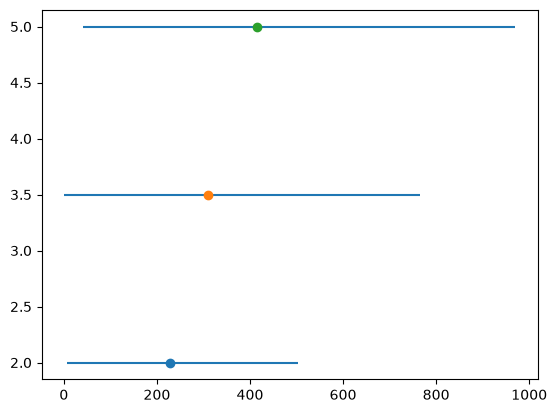

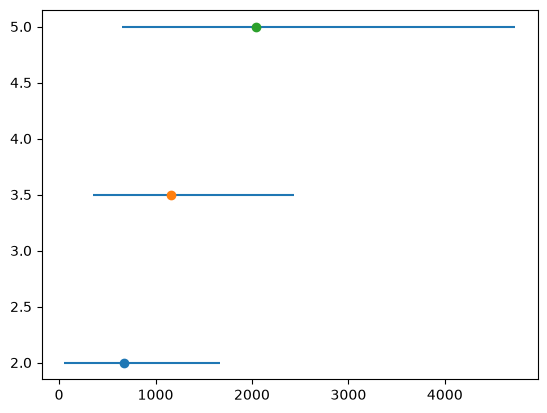

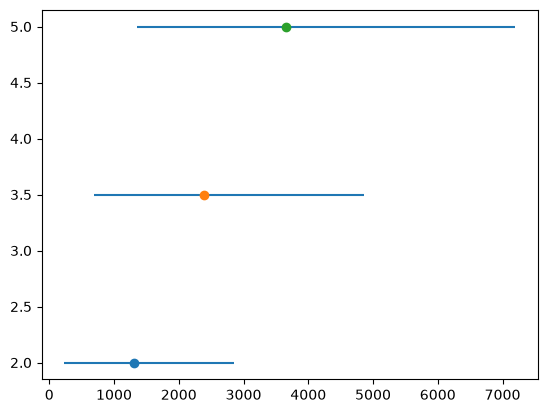

In [20]:
# ============================================================
# 9. FIGURE 2: TEMP VS SLR
# ============================================================

temp_map = {"2.0°C":2,"3.5°C":3.5,"5.0°C":5}

for year in [2100,2200,2300]:
    fig, ax = plt.subplots()

    for scen in df_total_ext["scenario_name"].unique():
        v = df_total_ext[
            (df_total_ext["time"]==year) &
            (df_total_ext["scenario_name"]==scen) &
            (df_total_ext["ice_sheet"]=="SLR")
        ]["value"]

        q = ranges(v)
        y = temp_map[scen]

        ax.hlines(y,q[1],q[3])
        ax.plot(q[2],y,"o")

    plt.show()
    plt.savefig(f"Fig2_{year}.png")
    plt.close()

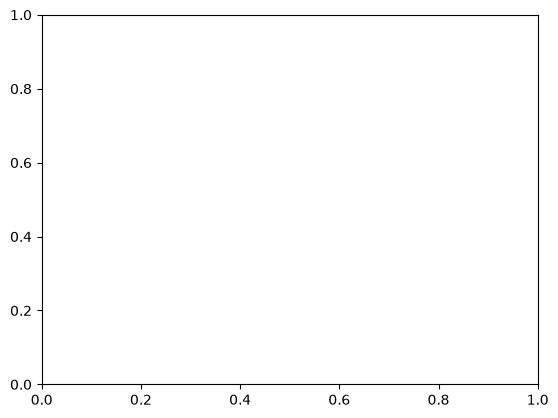

In [21]:
# ============================================================
# 10. FIGURE 3: WARMING VS SLR
# ============================================================

warming_map = {}  # <-- USER FILLS

df_total_ext["warming"] = df_total_ext.apply(
    lambda r: warming_map.get((r["scenario_name"],r["time"]),np.nan),
    axis=1
)

fig, ax = plt.subplots()

for (year,scen),g in df_total_ext.groupby(["time","scenario_name"]):
    if g["warming"].isna().all():
        continue

    q = ranges(g["value"])
    y = g["warming"].iloc[0]

    ax.hlines(y,q[1],q[3])
    ax.plot(q[2],y,"o")

plt.show()
plt.savefig("Fig3.png")
plt.close()

In [22]:
# ============================================================
# 11. FIGURE 4: PROCESS VIOLINS
# ============================================================

for year in [2100,2200,2300]:

    fig, ax = plt.subplots()

    subset = df_proc[df_proc["time"]==year]

    groups = []
    for proc in ["D","A","R"]:
        for ice in ["G","W","E"]:
            groups.append(
                subset[(subset["process"]==proc) &
                       (subset["ice_sheet"]==ice)]["value"]
            )

    ax.violinplot(groups, showmedians=False)

    plt.savefig(f"Fig4_{year}.png")
    plt.close()
    plt.show()

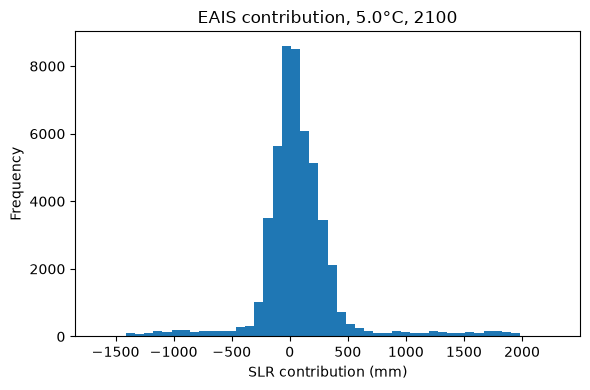

-286
-123
42
259
548


In [34]:
## Inspect data


# Select the data
subset = df_long[
    (df_long["time"] == 2100) &
    (df_long["scenario_name"] == "5.0°C") &
    (df_long["ice_sheet"] == "E") &
    (df_long["process"] == "TOTAL")
]

values = subset["value"]

# Plot histogram
plt.figure(figsize=(6, 4))
plt.hist(values, bins=50)

plt.xlabel("SLR contribution (mm)")
plt.ylabel("Frequency")
plt.title("EAIS contribution, 5.0°C, 2100")

plt.tight_layout()
plt.show()

print(f"{np.percentile(values,5):.0f}")
print(f"{np.percentile(values,17):.0f}")
print(f"{np.percentile(values,50):.0f}")
print(f"{np.percentile(values,83):.0f}")
print(f"{np.percentile(values,95):.0f}")

valuesEAIS=values

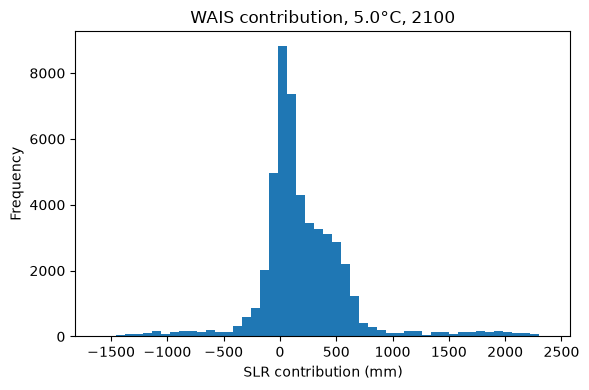

-263
-42
119
483
808


In [35]:

# Select the data
subset = df_long[
    (df_long["time"] == 2100) &
    (df_long["scenario_name"] == "5.0°C") &
    (df_long["ice_sheet"] == "W") &
    (df_long["process"] == "TOTAL")
]

values = subset["value"]

# Plot histogram
plt.figure(figsize=(6, 4))
plt.hist(values, bins=50)

plt.xlabel("SLR contribution (mm)")
plt.ylabel("Frequency")
plt.title("WAIS contribution, 5.0°C, 2100")

plt.tight_layout()
plt.show()

print(f"{np.percentile(values,5):.0f}")
print(f"{np.percentile(values,17):.0f}")
print(f"{np.percentile(values,50):.0f}")
print(f"{np.percentile(values,83):.0f}")
print(f"{np.percentile(values,95):.0f}")
valuesWAIS=values

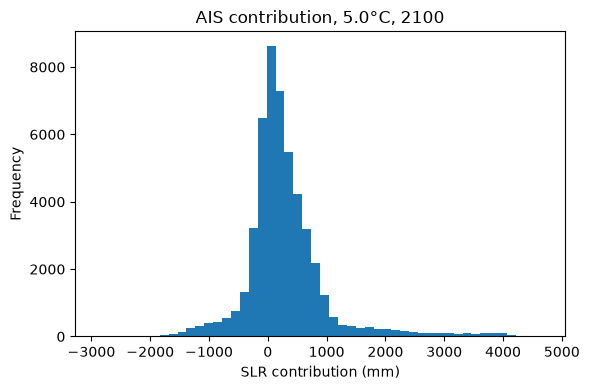

-573
-144
174
668
1468


In [36]:

# Select the data
subset = df_ais[
    (df_ais["time"] == 2100) &
    (df_ais["scenario_name"] == "5.0°C") &
    (df_ais["ice_sheet"] == "AIS") &
    (df_ais["process"] == "TOTAL")
]

values = subset["value"]

# Plot histogram
plt.figure(figsize=(6, 4))
plt.hist(values, bins=50)

plt.xlabel("SLR contribution (mm)")
plt.ylabel("Frequency")
plt.title("AIS contribution, 5.0°C, 2100")

plt.tight_layout()
plt.show()

print(f"{np.percentile(values,5):.0f}")
print(f"{np.percentile(values,17):.0f}")
print(f"{np.percentile(values,50):.0f}")
print(f"{np.percentile(values,83):.0f}")
print(f"{np.percentile(values,95):.0f}")
valuesAIS=values

Text(0, 0.5, 'total AIS')

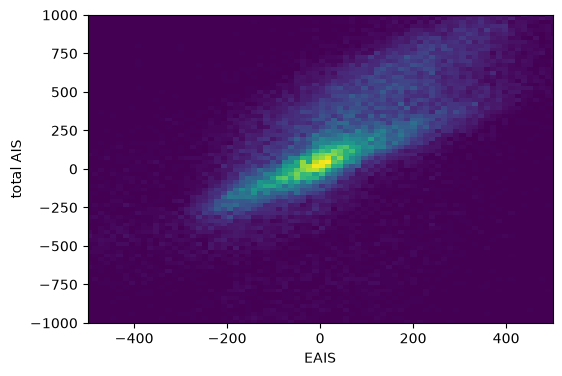

In [50]:
plt.figure(figsize=(6, 4))
plt.hist2d(valuesEAIS,valuesAIS,bins=300)
plt.xlim(-500,500)
plt.ylim(-1000,1000)
plt.xlabel('EAIS')
plt.ylabel('total AIS')

Text(0, 0.5, 'WIS')

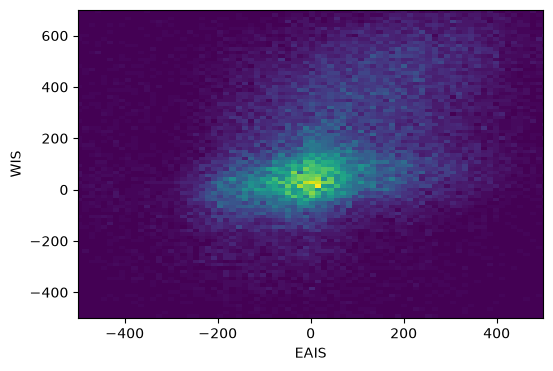

In [52]:
plt.figure(figsize=(6, 4))
plt.hist2d(valuesEAIS,valuesWAIS,bins=300)
plt.xlim(-500,500)
plt.ylim(-500,700)
plt.xlabel('EAIS')
plt.ylabel('WIS')